# Olist 电商数据可视化：10 种图表

数据来源：`report/tables_zh/` 与 `data/processed_zh/`（中文显示版）。

这个 notebook 用 10 种不同的图形回答 10 个业务问题：

1. 月度 GMV 与订单量如何变化？
2. 哪些品类贡献最多 GMV？
3. 支付金额由哪些支付方式构成？
4. 品类规模、评分与迟到率之间是什么关系？
5. GMV 在巴西各州如何分布？
6. 送达时长集中在什么区间？
7. 头部品类的订单金额分布差异有多大？
8. 不同首购月份的客户留存如何？
9. 卖家 GMV 是否高度集中？
10. 头部州份在规模、客单、评分、准时率和复购上谁更均衡？

所有图都会保存到 `report/figures/`，并在 notebook 中直接显示。

In [1]:
from pathlib import Path
import textwrap
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------------------
# 路径、字体和统一风格
# ---------------------------------------------------------------------------
ROOT = Path.cwd()
while not (ROOT / "report" / "tables_zh").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

TABLES = ROOT / "report" / "tables_zh"
PROCESSED = ROOT / "data" / "processed_zh"
FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update(
    {
        "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
        "axes.unicode_minus": False,
        "figure.dpi": 110,
        "savefig.dpi": 170,
        "axes.titlesize": 15,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

BLUE = "#1F4E79"
TEAL = "#2A9D8F"
ORANGE = "#F4A261"
RED = "#E76F51"
YELLOW = "#E9C46A"
GRAY = "#6C757D"
LIGHT = "#E5E7EB"
PALETTE = [BLUE, TEAL, ORANGE, RED, "#8E7DBE", YELLOW, "#4C9F70", GRAY]

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)


def read_table(name: str) -> pd.DataFrame:
    return pd.read_csv(TABLES / f"{name}.csv")


def style_axis(ax, grid_axis: str = "y"):
    ax.grid(axis=grid_axis, color=LIGHT, linewidth=0.9)
    ax.set_axisbelow(True)


def money_millions(value, _position=None):
    if abs(value) >= 10:
        return f"R${value:,.0f}M"
    return f"R${value:,.1f}M"


def save_and_show(fig, filename: str):
    fig.savefig(FIG_DIR / f"{filename}.png", bbox_inches="tight", facecolor="white")
    plt.show()


# 读取图表底表
monthly = read_table("monthly_kpis_zh")
category = read_table("category_kpis_zh")
payment = read_table("payment_type_kpis_zh")
state = read_table("state_kpis_zh")
seller = read_table("seller_kpis_zh")
cohort = read_table("cohort_retention_wide_zh")

orders = pd.read_csv(
    PROCESSED / "orders_master_zh.csv",
    usecols=["是否送达", "送达天数"],
)
order_category = pd.read_csv(
    PROCESSED / "order_category_zh.csv",
    usecols=["品类（中文）", "含运费金额", "是否有效订单"],
)

print("图表底表已加载：", len(monthly), "个月；", len(category), "个品类；", len(state), "个州")
print("图片输出目录：", FIG_DIR)

图表底表已加载： 20 个月； 74 个品类； 27 个州
图片输出目录： E:\workbuddy-space\ecommerce-analysis\report\figures


## 图 1｜双轴组合图：月度 GMV 与有效订单

**怎么读**：柱形是商品 GMV，折线是有效订单数；两者共用一个时间轴，但左右轴单位不同。

**业务含义**：2017-11 是黑五峰值，GMV 和订单同时上升；如果只有 GMV 上升而订单不涨，说明是客单价驱动。

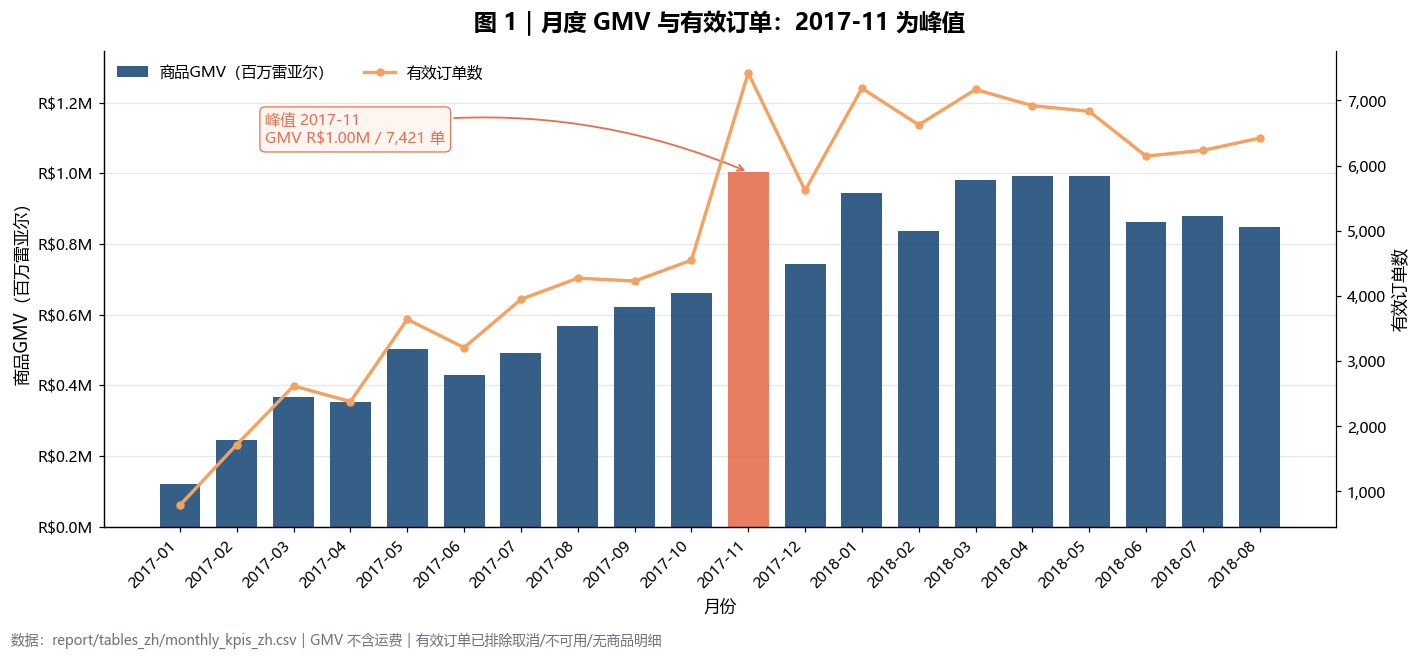

In [2]:
monthly = monthly.sort_values("月份").reset_index(drop=True)
x = np.arange(len(monthly))
peak_idx = int(monthly["商品GMV"].idxmax())
colors = [RED if i == peak_idx else BLUE for i in range(len(monthly))]

fig, ax1 = plt.subplots(figsize=(13, 5.8))
bars = ax1.bar(
    x,
    monthly["商品GMV"] / 1e6,
    color=colors,
    width=0.72,
    alpha=0.9,
    label="商品GMV（百万雷亚尔）",
)
ax1.set_ylabel("商品GMV（百万雷亚尔）")
ax1.set_xlabel("月份")
ax1.set_xticks(x)
ax1.set_xticklabels(monthly["月份"], rotation=45, ha="right")
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(money_millions))
style_axis(ax1, "y")

ax2 = ax1.twinx()
ax2.plot(
    x,
    monthly["有效订单数"],
    color=ORANGE,
    marker="o",
    markersize=4.5,
    linewidth=2.2,
    label="有效订单数",
)
ax2.set_ylabel("有效订单数")
ax2.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax2.spines["right"].set_visible(True)

peak = monthly.loc[peak_idx]
ax1.set_ylim(0, monthly["商品GMV"].max() / 1e6 * 1.34)
ax1.annotate(
    f"峰值 {peak['月份']}\nGMV R${peak['商品GMV']/1e6:.2f}M / {int(peak['有效订单数']):,} 单",
    xy=(peak_idx, peak["商品GMV"] / 1e6),
    xytext=(1.5, monthly["商品GMV"].max() / 1e6 * 1.12),
    fontsize=10,
    color=RED,
    va="center",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#FFF5F0", edgecolor=RED, linewidth=0.8),
    arrowprops=dict(arrowstyle="->", color=RED, lw=1.2, connectionstyle="arc3,rad=-0.15"),
)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", frameon=False, ncol=2)
ax1.set_title("图 1｜月度 GMV 与有效订单：2017-11 为峰值", pad=14)
fig.text(
    0.01,
    -0.02,
    "数据：report/tables_zh/monthly_kpis_zh.csv｜GMV 不含运费｜有效订单已排除取消/不可用/无商品明细",
    fontsize=9,
    color=GRAY,
)
fig.tight_layout()
save_and_show(fig, "01_monthly_gmv_orders")

## 图 2｜横向条形图：品类 GMV Top 10

**怎么读**：条形长度是 GMV，右侧标签是该品类占全部 GMV 的比例。

**业务含义**：品类集中度不高，第一名美妆个护只占约 9.3%，没有单一品类依赖。

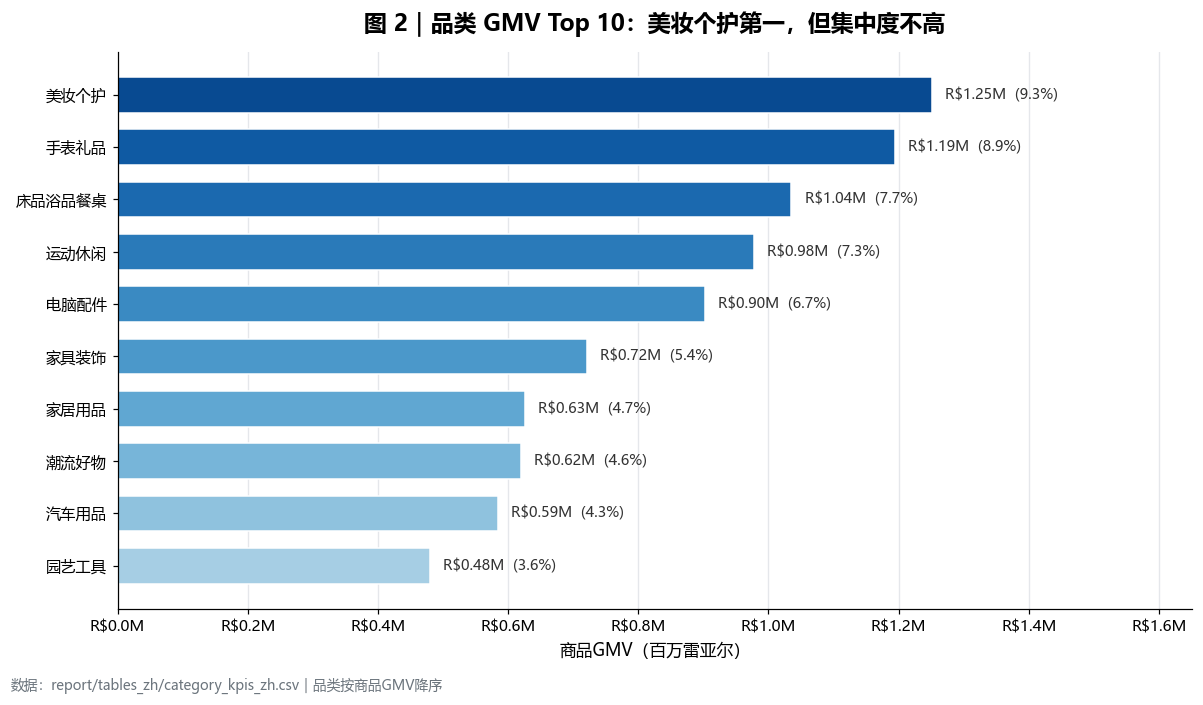

In [3]:
top_category = category.head(10).sort_values("商品GMV", ascending=True).copy()
bar_colors = plt.cm.Blues(np.linspace(0.35, 0.9, len(top_category)))

fig, ax = plt.subplots(figsize=(11, 6.2))
bars = ax.barh(
    top_category["品类"],
    top_category["商品GMV"] / 1e6,
    color=bar_colors,
    edgecolor="white",
    height=0.68,
)
for bar, value, share in zip(
    bars, top_category["商品GMV"] / 1e6, top_category["GMV占比"]
):
    ax.text(
        value + 0.02,
        bar.get_y() + bar.get_height() / 2,
        f"R${value:.2f}M  ({share:.1%})",
        va="center",
        fontsize=9.5,
        color="#333333",
    )

ax.set_xlabel("商品GMV（百万雷亚尔）")
ax.set_ylabel("")
ax.set_xlim(0, top_category["商品GMV"].max() / 1e6 * 1.32)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(money_millions))
style_axis(ax, "x")
ax.set_title("图 2｜品类 GMV Top 10：美妆个护第一，但集中度不高", pad=14)
fig.text(
    0.01,
    -0.02,
    "数据：report/tables_zh/category_kpis_zh.csv｜品类按商品GMV降序",
    fontsize=9,
    color=GRAY,
)
fig.tight_layout()
save_and_show(fig, "02_category_top10")

## 图 3｜环形图：支付金额构成

**怎么读**：环的每一段是支付金额占比；中间是支付总额。

**业务含义**：信用卡占支付金额约 78.5%，是绝对主力；代金券金额占比很小，但会出现在部分订单中。

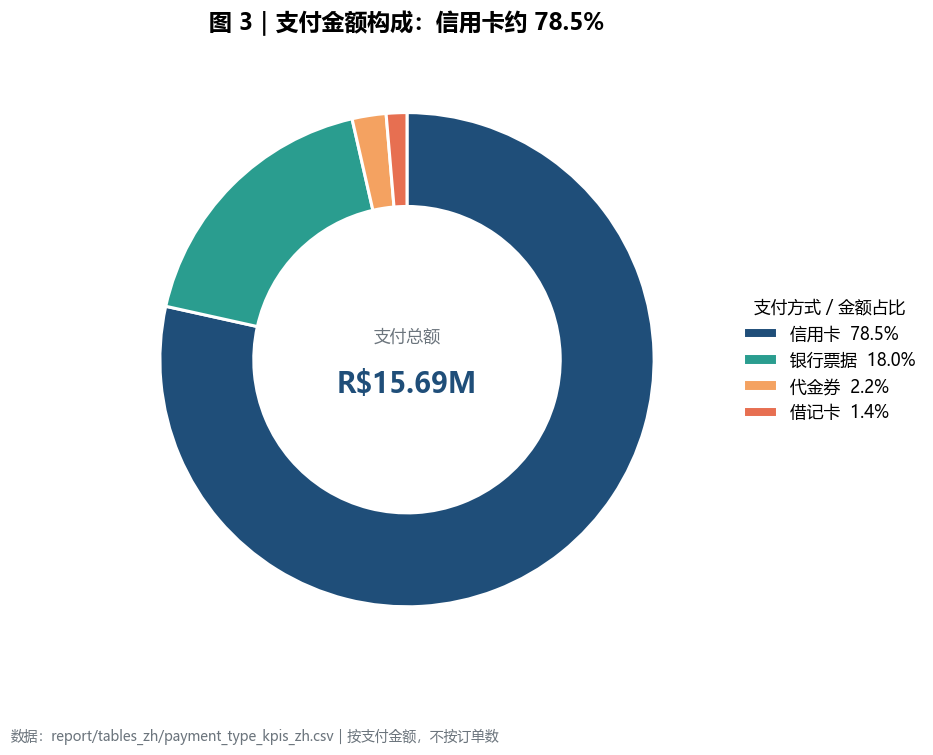

In [4]:
pay = payment.sort_values("支付金额占比", ascending=False).copy()
fig, ax = plt.subplots(figsize=(10.0, 7.2))
wedges, _ = ax.pie(
    pay["支付金额占比"],
    startangle=90,
    counterclock=False,
    colors=[BLUE, TEAL, ORANGE, RED, GRAY][: len(pay)],
    wedgeprops=dict(width=0.38, edgecolor="white", linewidth=2),
    textprops=dict(fontsize=11),
)
legend_labels = [
    f"{row['支付方式']}  {row['支付金额占比']:.1%}"
    for _, row in pay.iterrows()
]
ax.legend(
    wedges,
    legend_labels,
    title="支付方式 / 金额占比",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=11,
    title_fontsize=11,
)

ax.text(
    0,
    0.10,
    "支付总额",
    ha="center",
    va="center",
    fontsize=11,
    color=GRAY,
)
ax.text(
    0,
    -0.10,
    f"R${pay['支付金额'].sum()/1e6:.2f}M",
    ha="center",
    va="center",
    fontsize=18,
    fontweight="bold",
    color=BLUE,
)
ax.set_title("图 3｜支付金额构成：信用卡约 78.5%", pad=14)
fig.text(
    0.01,
    0.01,
    "数据：report/tables_zh/payment_type_kpis_zh.csv｜按支付金额，不按订单数",
    fontsize=9,
    color=GRAY,
)
fig.subplots_adjust(left=0.02, right=0.72, top=0.88, bottom=0.10)
save_and_show(fig, "03_payment_donut")

## 图 4｜气泡散点图：品类规模 × 评分 × 订单量 × 迟到率

**怎么读**：横轴是 GMV（对数轴），纵轴是评论分，气泡大小是有效订单数，颜色是迟到率。

**业务含义**：右上象限是“规模大、评分高”的品类；红色气泡提示规模不小但履约体验偏弱，值得单独排查。

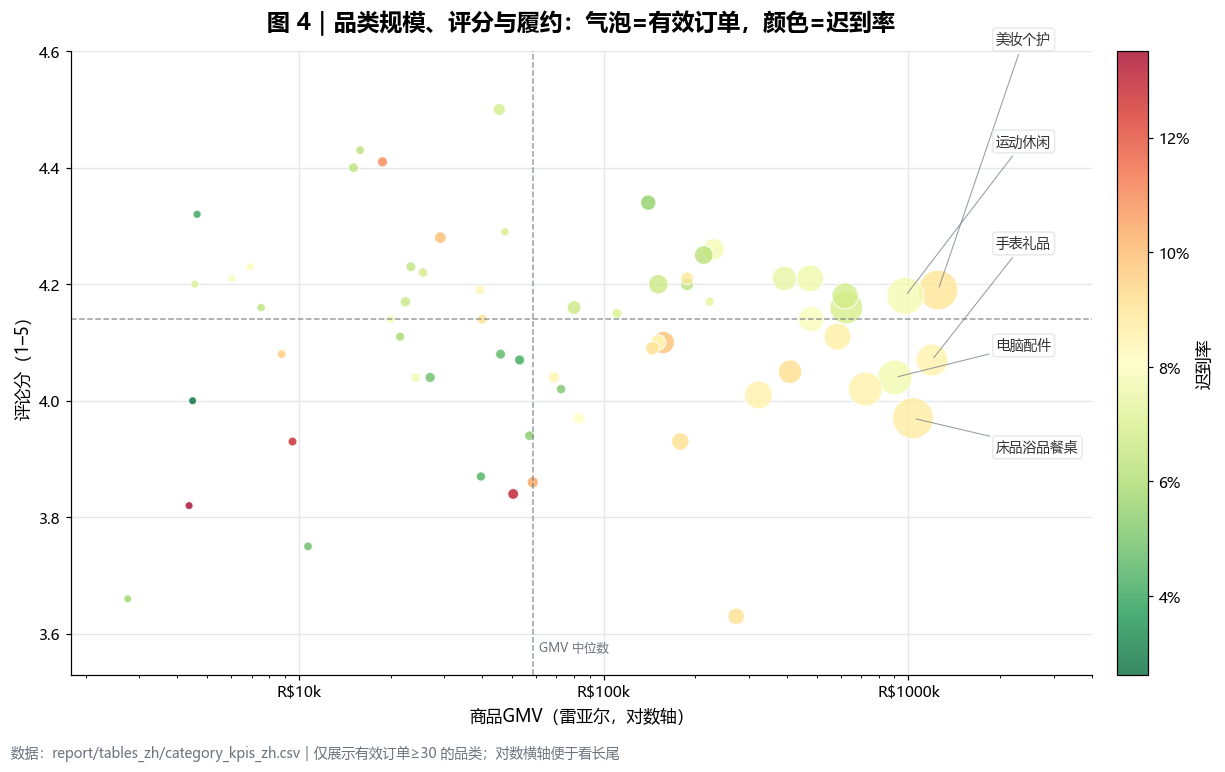

In [5]:
cat = category.copy()
cat["评论分"] = pd.to_numeric(cat["评论分"], errors="coerce")
cat["迟到率"] = pd.to_numeric(cat["迟到率"], errors="coerce")
cat["有效订单数"] = pd.to_numeric(cat["有效订单数"], errors="coerce")
cat = cat[(cat["有效订单数"] >= 30) & cat["评论分"].notna() & cat["迟到率"].notna()].copy()

sizes = 25 + 700 * (cat["有效订单数"] / cat["有效订单数"].max())
norm = Normalize(vmin=cat["迟到率"].min(), vmax=cat["迟到率"].max())
cmap = plt.cm.RdYlGn_r

fig, ax = plt.subplots(figsize=(12, 6.8))
scatter = ax.scatter(
    cat["商品GMV"],
    cat["评论分"],
    s=sizes,
    c=cat["迟到率"],
    cmap=cmap,
    norm=norm,
    alpha=0.78,
    edgecolors="white",
    linewidths=0.8,
)
ax.set_xscale("log")
ax.set_xlabel("商品GMV（雷亚尔，对数轴）")
ax.set_ylabel("评论分（1–5）")
ax.set_ylim(max(2.4, cat["评论分"].min() - 0.1), min(4.9, cat["评论分"].max() + 0.1))
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda value, pos: f"R${value/1000:.0f}k"))

# 参考线
ax.axhline(cat["评论分"].median(), color=GRAY, linestyle="--", linewidth=1, alpha=0.7)
ax.axvline(cat["商品GMV"].median(), color=GRAY, linestyle="--", linewidth=1, alpha=0.7)
ax.text(
    cat["商品GMV"].median() * 1.05,
    ax.get_ylim()[0] + 0.04,
    "GMV 中位数",
    fontsize=8,
    color=GRAY,
)

# 标注 Top 5 品类：统一放在右侧，按评分上下错开，避免互相遮挡
top5 = cat.nlargest(5, "商品GMV").sort_values("评论分", ascending=False)
label_x = cat["商品GMV"].max() * 1.55
label_ys = np.linspace(4.62, 3.92, len(top5))
for (_, row), label_y in zip(top5.iterrows(), label_ys):
    ax.annotate(
        row["品类"],
        xy=(row["商品GMV"], row["评论分"]),
        xytext=(label_x, label_y),
        fontsize=9,
        color="#333333",
        ha="left",
        va="center",
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=LIGHT, alpha=0.9),
        arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.7, alpha=0.7),
    )

ax.set_xlim(cat["商品GMV"].min() * 0.65, cat["商品GMV"].max() * 3.2)

cbar = fig.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label("迟到率")
cbar.ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
style_axis(ax, "both")
ax.set_title("图 4｜品类规模、评分与履约：气泡=有效订单，颜色=迟到率", pad=14)
fig.text(
    0.01,
    -0.02,
    "数据：report/tables_zh/category_kpis_zh.csv｜仅展示有效订单≥30 的品类；对数横轴便于看长尾",
    fontsize=9,
    color=GRAY,
)
fig.tight_layout()
save_and_show(fig, "04_category_bubble")

## 图 5｜地理气泡图：州级 GMV 与迟到率

**怎么读**：每个点是一个州（按该州客户经纬度均值定位），点越大 GMV 越高，颜色越红迟到率越高。

**业务含义**：SP、RJ、MG 是规模中心；北部/东北部部分州规模不大但迟到率偏高，适合做物流专题。

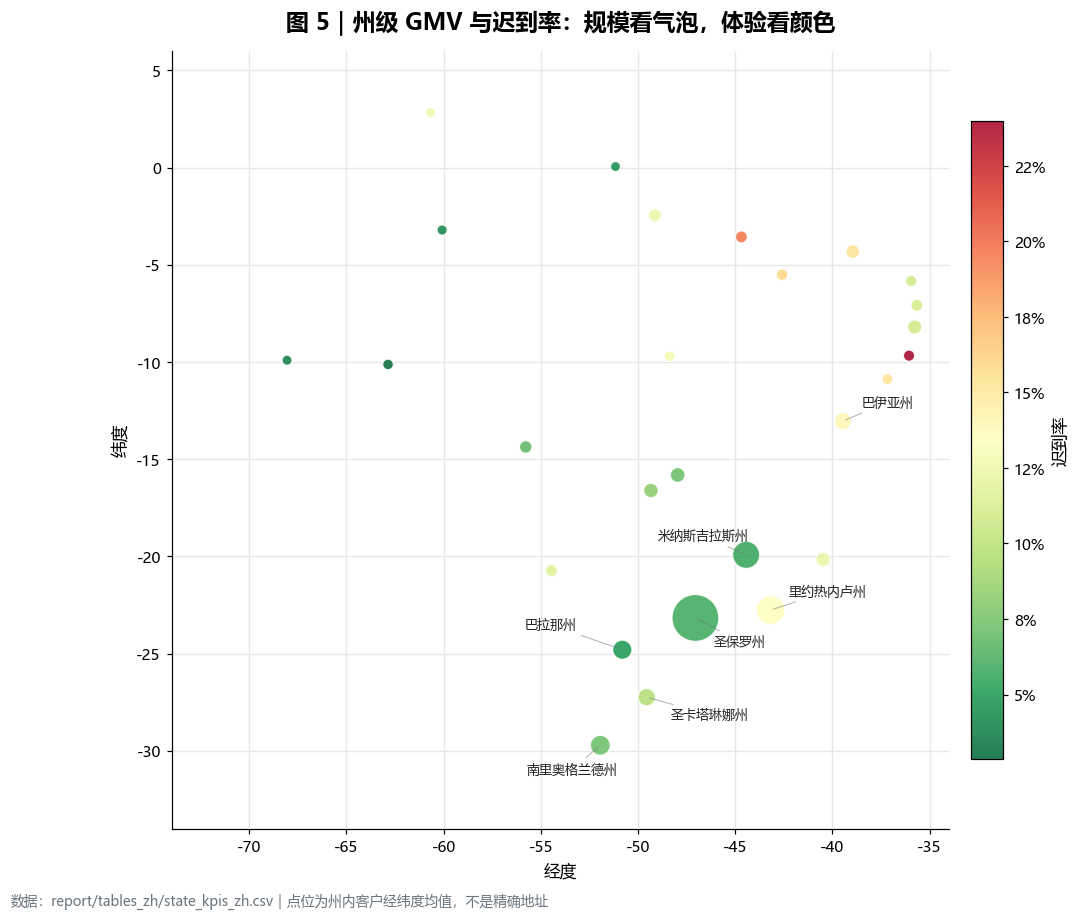

In [6]:
st = state.copy()
st["商品GMV"] = pd.to_numeric(st["商品GMV"], errors="coerce")
st["迟到率"] = pd.to_numeric(st["迟到率"], errors="coerce")
st = st.dropna(subset=["客户纬度", "客户经度", "商品GMV", "迟到率"]).copy()
st["气泡大小"] = 40 + 900 * (st["商品GMV"] / st["商品GMV"].max())

fig, ax = plt.subplots(figsize=(10.5, 8.2))
scatter = ax.scatter(
    st["客户经度"],
    st["客户纬度"],
    s=st["气泡大小"],
    c=st["迟到率"],
    cmap="RdYlGn_r",
    alpha=0.85,
    edgecolors="white",
    linewidths=0.8,
)
label_offsets = {
    "圣保罗州": (12, -18),
    "里约热内卢州": (12, 10),
    "米纳斯吉拉斯州": (-58, 10),
    "南里奥格兰德州": (-48, -18),
    "巴拉那州": (-64, 14),
    "圣卡塔琳娜州": (16, -14),
    "巴伊亚州": (12, 10),
}
for _, row in st.nlargest(7, "商品GMV").iterrows():
    offset = label_offsets.get(row["州"], (7, 5))
    ax.annotate(
        row["州"],
        xy=(row["客户经度"], row["客户纬度"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=8.5,
        color="#222222",
        arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.6, alpha=0.6),
    )

ax.set_xlim(-74, -34)
ax.set_ylim(-34, 6)
ax.set_xlabel("经度")
ax.set_ylabel("纬度")
ax.set_aspect("equal", adjustable="box")
style_axis(ax, "both")
cbar = fig.colorbar(scatter, ax=ax, pad=0.02, shrink=0.82)
cbar.set_label("迟到率")
cbar.ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("图 5｜州级 GMV 与迟到率：规模看气泡，体验看颜色", pad=14)
fig.text(
    0.01,
    -0.01,
    "数据：report/tables_zh/state_kpis_zh.csv｜点位为州内客户经纬度均值，不是精确地址",
    fontsize=9,
    color=GRAY,
)
fig.tight_layout()
save_and_show(fig, "05_state_bubble_map")

## 图 6｜直方图：送达天数分布

**怎么读**：横轴是实际送达天数，纵轴是订单数；虚线是均值和中位数。

**业务含义**：大多数订单 8–15 天送达，长尾在 30 天以上；长尾订单正是迟到率和差评的高发区。

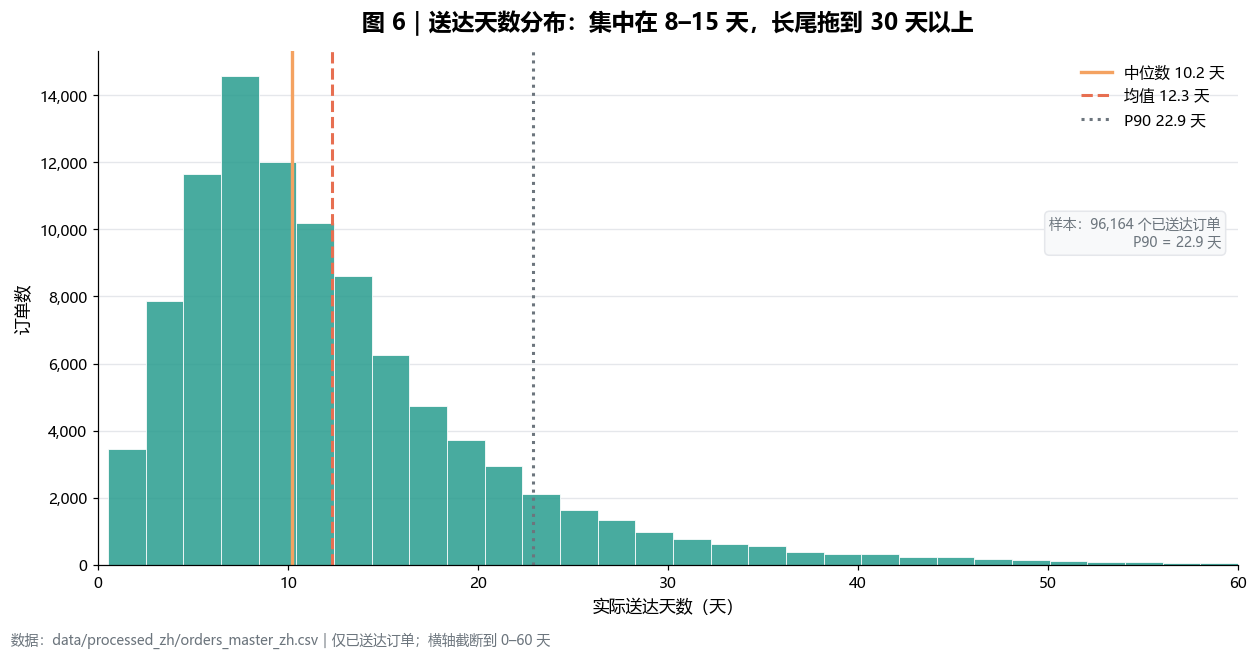

In [7]:
delivered_days = orders.loc[orders["是否送达"].eq("是"), "送达天数"].dropna()
delivered_days = delivered_days[(delivered_days >= 0) & (delivered_days <= 60)]

fig, ax = plt.subplots(figsize=(11.5, 5.8))
n, bins, patches = ax.hist(
    delivered_days,
    bins=30,
    color=TEAL,
    alpha=0.86,
    edgecolor="white",
    linewidth=0.6,
)
median_days = delivered_days.median()
mean_days = delivered_days.mean()
p90_days = delivered_days.quantile(0.90)

ax.axvline(median_days, color=ORANGE, linestyle="-", linewidth=2.2, label=f"中位数 {median_days:.1f} 天")
ax.axvline(mean_days, color=RED, linestyle="--", linewidth=2.0, label=f"均值 {mean_days:.1f} 天")
ax.axvline(p90_days, color=GRAY, linestyle=":", linewidth=2.0, label=f"P90 {p90_days:.1f} 天")

ax.set_xlabel("实际送达天数（天）")
ax.set_ylabel("订单数")
ax.set_xlim(0, 60)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
style_axis(ax, "y")
ax.legend(loc="upper right", frameon=False)
ax.set_title("图 6｜送达天数分布：集中在 8–15 天，长尾拖到 30 天以上", pad=14)
ax.text(
    0.985,
    0.62,
    f"样本：{len(delivered_days):,} 个已送达订单\nP90 = {p90_days:.1f} 天",
    transform=ax.transAxes,
    ha="right",
    fontsize=9,
    color=GRAY,
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#F8F9FA", edgecolor=LIGHT),
)
fig.text(
    0.01,
    -0.02,
    "数据：data/processed_zh/orders_master_zh.csv｜仅已送达订单；横轴截断到 0–60 天",
    fontsize=9,
    color=GRAY,
)
fig.tight_layout()
save_and_show(fig, "06_delivery_histogram")

## 图 7｜箱线图：头部品类订单金额分布

**怎么读**：每个箱体展示该品类订单金额的中位数、四分位数和须；纵轴用对数刻度，因为金额跨度很大。

**业务含义**：美妆个护、手表礼品等品类的中位金额和长尾不同；做品类定价/包邮门槛时要分开看。

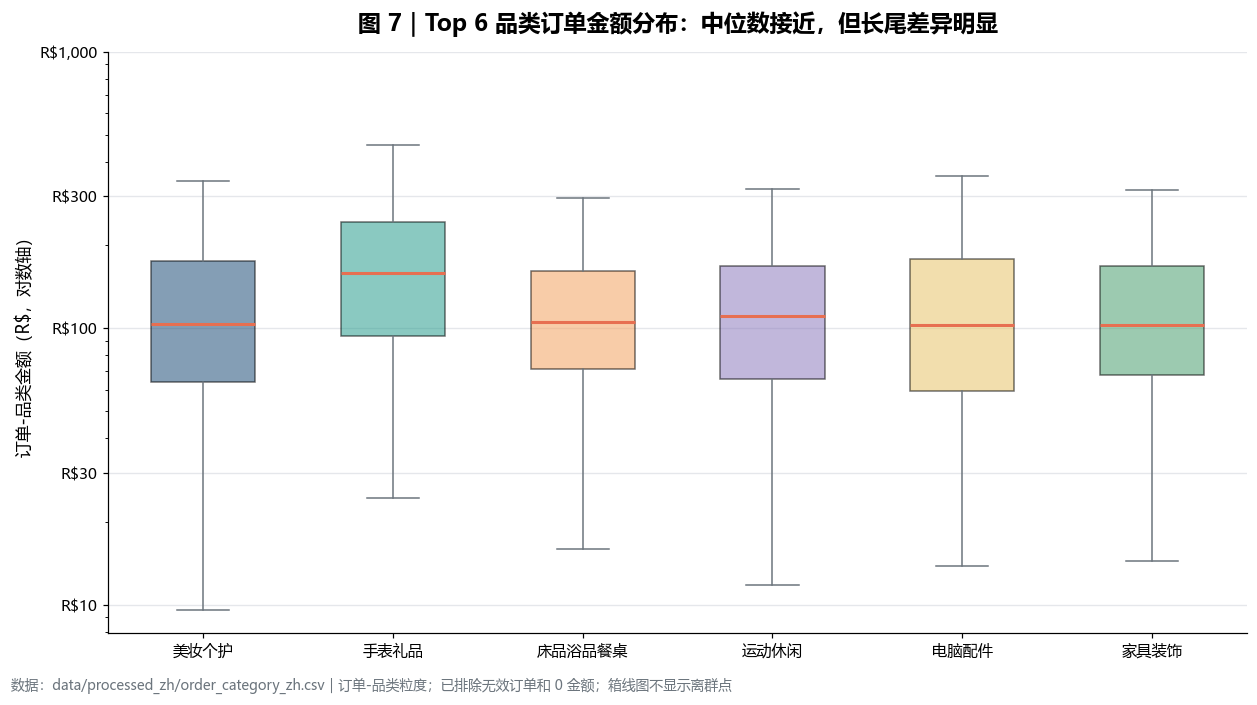

In [8]:
oc = order_category.copy()
oc = oc[oc["是否有效订单"].eq("是")].copy()
oc["含运费金额"] = pd.to_numeric(oc["含运费金额"], errors="coerce")
oc = oc[oc["含运费金额"] > 0].copy()

top6 = (
    oc.groupby("品类（中文）")["含运费金额"]
    .sum()
    .nlargest(6)
    .index
    .tolist()
)
box_data = [
    oc.loc[oc["品类（中文）"].eq(name), "含运费金额"].values
    for name in top6
]
box_labels = [textwrap.fill(name, 8) for name in top6]

fig, ax = plt.subplots(figsize=(11.5, 6.2))
bp = ax.boxplot(
    box_data,
    labels=box_labels,
    patch_artist=True,
    showfliers=False,
    widths=0.55,
    medianprops=dict(color=RED, linewidth=2),
    whiskerprops=dict(color=GRAY, linewidth=1),
    capprops=dict(color=GRAY, linewidth=1),
    boxprops=dict(linewidth=1),
)
for patch, color in zip(bp["boxes"], [BLUE, TEAL, ORANGE, "#8E7DBE", YELLOW, "#4C9F70"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.55)

ax.set_yscale("log")
ax.set_yticks([10, 30, 100, 300, 1000])
ax.set_ylabel("订单-品类金额（R$，对数轴）")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda value, pos: f"R${value:,.0f}"))
style_axis(ax, "y")
ax.set_title("图 7｜Top 6 品类订单金额分布：中位数接近，但长尾差异明显", pad=14)
fig.text(
    0.01,
    -0.02,
    "数据：data/processed_zh/order_category_zh.csv｜订单-品类粒度；已排除无效订单和 0 金额；箱线图不显示离群点",
    fontsize=9,
    color=GRAY,
)
fig.tight_layout()
save_and_show(fig, "07_category_boxplot")

## 图 8｜热力图：Cohort 留存

**怎么读**：每一行是一个首购月份 cohort，每一列是首购后第 N 个月；颜色越深，留存率越高。

**业务含义**：这张图刻意从“第 1 月”开始，避免第 0 月 100% 把颜色压平。整体留存低于 1%，说明复购极低，运营重点应是首购转二次购买。

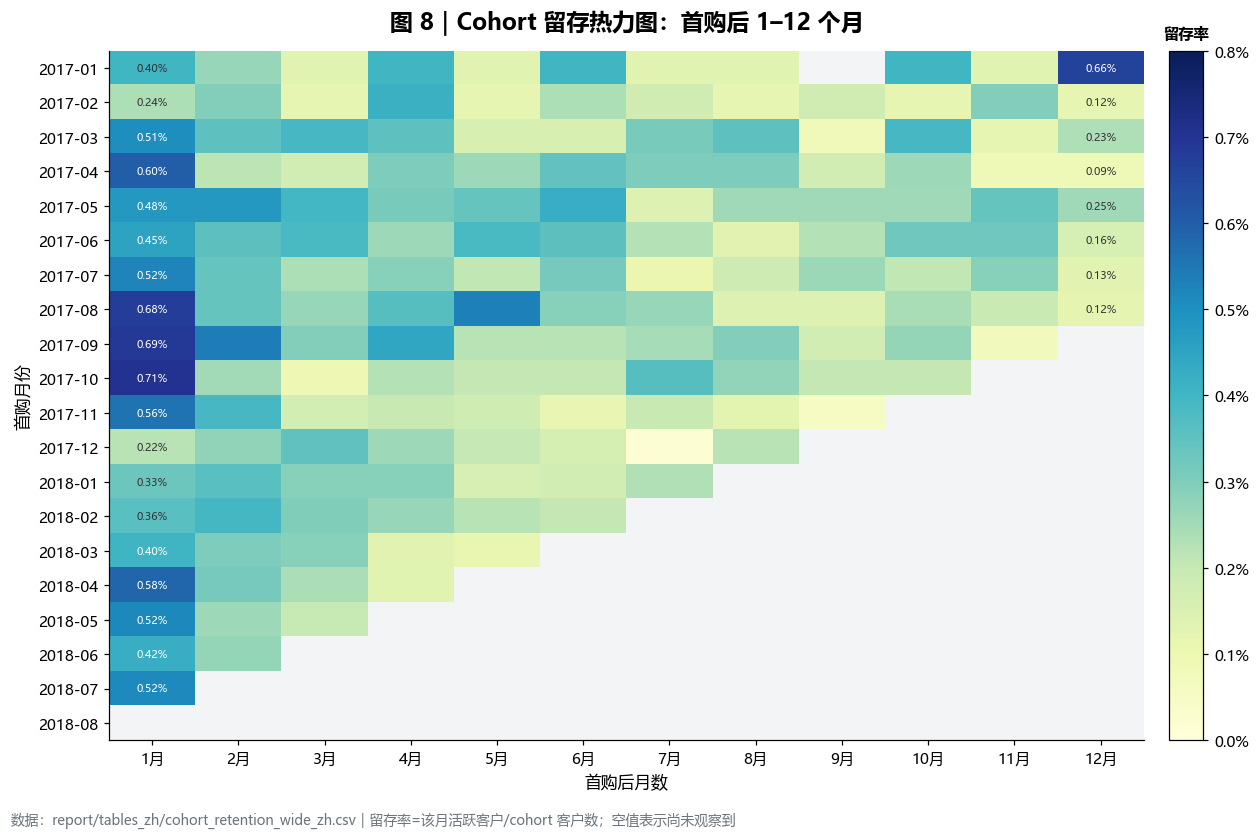

In [9]:
cohort_matrix = cohort.set_index("首购月份")
period_cols = [column for column in cohort_matrix.columns if column.startswith("第")][1:13]
heat = cohort_matrix[period_cols].astype(float)

fig, ax = plt.subplots(figsize=(12.5, 7.4))
masked = np.ma.masked_invalid(heat.values)
cmap = plt.cm.YlGnBu.copy()
cmap.set_bad("#F3F4F6")
im = ax.imshow(
    masked,
    aspect="auto",
    cmap=cmap,
    vmin=0,
    vmax=max(0.008, np.nanpercentile(heat.values, 99)),
)

ax.set_xticks(np.arange(len(period_cols)))
ax.set_xticklabels([column.replace("第", "").replace("月", "") + "月" for column in period_cols])
ax.set_yticks(np.arange(len(heat.index)))
ax.set_yticklabels(heat.index)
ax.set_xlabel("首购后月数")
ax.set_ylabel("首购月份")
ax.set_title("图 8｜Cohort 留存热力图：首购后 1–12 个月", pad=14)

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.ax.set_title("留存率", fontsize=10, pad=8)
cbar.ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))

# 只在第一列和最后一列加少量数值，避免 260 个格子都写字
for row_idx in range(len(heat.index)):
    for col_idx in [0, 11]:
        value = heat.values[row_idx, col_idx]
        if pd.notna(value):
            ax.text(
                col_idx,
                row_idx,
                f"{value:.2%}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if value > 0.004 else "#333333",
            )

fig.text(
    0.01,
    -0.02,
    "数据：report/tables_zh/cohort_retention_wide_zh.csv｜留存率=该月活跃客户/cohort 客户数；空值表示尚未观察到",
    fontsize=9,
    color=GRAY,
)
fig.tight_layout()
save_and_show(fig, "08_cohort_heatmap")

## 图 9｜帕累托图：卖家 GMV 集中度

**怎么读**：柱形是单个卖家的 GMV，折线是累计 GMV 占比；横轴是卖家排名。

**业务含义**：前 100 个卖家累计贡献约 45% 的 GMV，长尾很长；不是典型 80/20，头部依赖度中等。

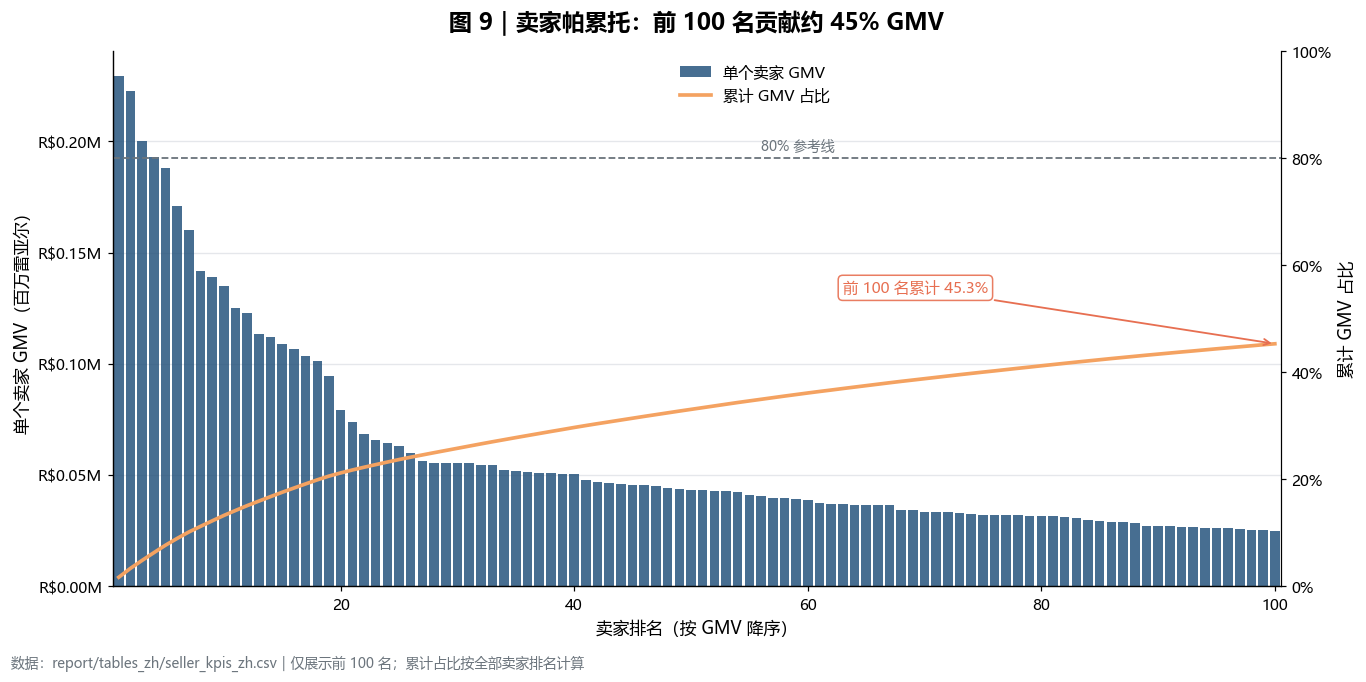

In [10]:
sel = seller.sort_values("卖家排名").head(100).copy()
sel["商品GMV"] = pd.to_numeric(sel["商品GMV"], errors="coerce")
sel["累计GMV占比"] = pd.to_numeric(sel["累计GMV占比"], errors="coerce")

fig, ax1 = plt.subplots(figsize=(12.5, 6.0))
ax1.bar(
    sel["卖家排名"],
    sel["商品GMV"] / 1e6,
    color=BLUE,
    width=0.82,
    alpha=0.82,
    label="单个卖家 GMV",
)
ax1.set_xlabel("卖家排名（按 GMV 降序）")
ax1.set_ylabel("单个卖家 GMV（百万雷亚尔）")
ax1.set_xlim(0.5, 100.5)
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda value, pos: f"R${value:,.2f}M"))
style_axis(ax1, "y")

ax2 = ax1.twinx()
ax2.plot(
    sel["卖家排名"],
    sel["累计GMV占比"],
    color=ORANGE,
    linewidth=2.4,
    label="累计 GMV 占比",
)
ax2.set_ylabel("累计 GMV 占比")
ax2.set_ylim(0, 1)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax2.axhline(0.8, color=GRAY, linestyle="--", linewidth=1.2)
ax2.text(56, 0.815, "80% 参考线", fontsize=9, color=GRAY)
ax2.spines["right"].set_visible(True)

last_cum = sel["累计GMV占比"].iloc[-1]
ax2.annotate(
    f"前 100 名累计 {last_cum:.1%}",
    xy=(100, last_cum),
    xytext=(63, 0.55),
    fontsize=10,
    color=RED,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=RED, alpha=0.9),
    arrowprops=dict(arrowstyle="->", color=RED, lw=1.2),
)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.55, 1.0),
    frameon=True,
    facecolor="white",
    framealpha=0.9,
    edgecolor="none",
)
ax1.set_title("图 9｜卖家帕累托：前 100 名贡献约 45% GMV", pad=14)
fig.text(
    0.01,
    -0.02,
    "数据：report/tables_zh/seller_kpis_zh.csv｜仅展示前 100 名；累计占比按全部卖家排名计算",
    fontsize=9,
    color=GRAY,
)
fig.tight_layout()
save_and_show(fig, "09_seller_pareto")

## 图 10｜雷达图：Top 5 州的多指标对比

**怎么读**：每个轴是一个指标，均归一化到 0–1；越靠外表示相对表现越好。

**业务含义**：SP 规模最大但客单价不突出；RJ 规模第二但准时率和评分偏弱；MG 在评分和准时率上更均衡。

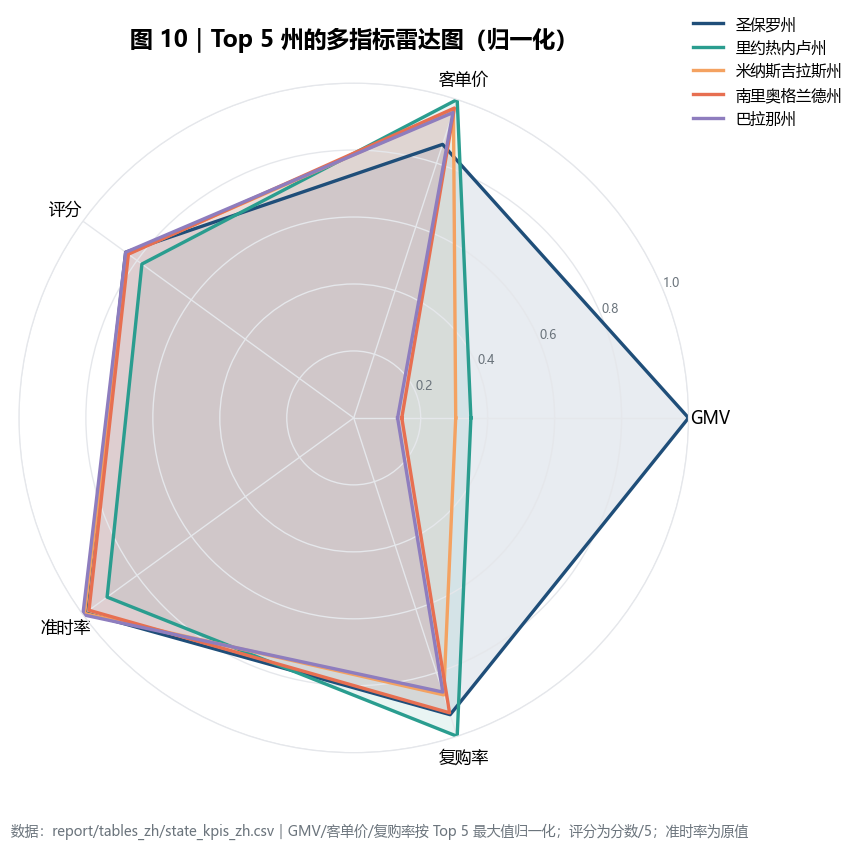

In [11]:
top_states = state.head(5).copy()
metric_specs = [
    ("GMV", "商品GMV", False),
    ("客单价", "客单价", False),
    ("评分", "评论分", True),
    ("准时率", "准时率", False),
    ("复购率", "复购客户率", False),
]

radar = top_states[["州"] + [column for _, column, _ in metric_specs]].copy()
for label, column, already_ratio in metric_specs:
    values = pd.to_numeric(radar[column], errors="coerce")
    if label == "评分":
        radar[label] = values / 5
    else:
        radar[label] = values / values.max()

labels = [label for label, _, _ in metric_specs]
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7.8, 7.8), subplot_kw=dict(polar=True))
for idx, (_, row) in enumerate(radar.iterrows()):
    values = [row[label] for label in labels]
    values += values[:1]
    color = PALETTE[idx % len(PALETTE)]
    ax.plot(angles, values, linewidth=2.2, color=color, label=row["州"])
    ax.fill(angles, values, color=color, alpha=0.10)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", "1.0"], fontsize=8, color=GRAY)
ax.grid(color=LIGHT, linewidth=0.9)
ax.spines["polar"].set_color(LIGHT)
ax.set_title("图 10｜Top 5 州的多指标雷达图（归一化）", pad=24)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.12), frameon=False)
fig.text(
    0.01,
    -0.02,
    "数据：report/tables_zh/state_kpis_zh.csv｜GMV/客单价/复购率按 Top 5 最大值归一化；评分为分数/5；准时率为原值",
    fontsize=9,
    color=GRAY,
)
fig.tight_layout()
save_and_show(fig, "10_state_radar")

## 图表清单与复用

| 图 | 类型 | 回答的问题 | 主要数据 |
|---|---|---|---|
| 1 | 双轴组合图 | 月度 GMV 与订单 | `monthly_kpis_zh` |
| 2 | 横向条形图 | 品类 Top 10 | `category_kpis_zh` |
| 3 | 环形图 | 支付金额构成 | `payment_type_kpis_zh` |
| 4 | 气泡散点图 | 品类规模/评分/迟到率 | `category_kpis_zh` |
| 5 | 地理气泡图 | 州级 GMV 与迟到率 | `state_kpis_zh` |
| 6 | 直方图 | 送达天数分布 | `orders_master_zh` |
| 7 | 箱线图 | 头部品类金额分布 | `order_category_zh` |
| 8 | 热力图 | Cohort 留存 | `cohort_retention_wide_zh` |
| 9 | 帕累托图 | 卖家 GMV 集中度 | `seller_kpis_zh` |
| 10 | 雷达图 | Top 5 州多指标对比 | `state_kpis_zh` |

所有图片已保存到 `report/figures/`，文件名是 `01_...png` 到 `10_...png`。

**改图建议**

- 换配色：修改 `PALETTE` 和 `BLUE/TEAL/...`。
- 换字体：修改 `plt.rcParams["font.sans-serif"]`。
- 换分析范围：在读取 CSV 前过滤月份、州或品类。
- 想导出 SVG/PDF：把 `fig.savefig(..., dpi=170)` 改成 `.svg` 或 `.pdf`。
- 图表口径仍以 `report/analysis_guide.md` 为准；本 notebook 只做展示，不重新计算指标。